# SerialFlavour paper figures

Run all cells to display Figures 1–7 in paper order. Figure 1 is loaded from the paper's bundled PNG. Figures 2–7 are regenerated from the prepared JSON files with the scripts in this directory. The regenerated images are written to a temporary directory for this kernel session.

In the Python environment used by your Jupyter kernel, install the plotting dependencies with `python -m pip install -r requirements.txt` from the `plots` directory.

In [1]:
from pathlib import Path
import subprocess
import sys
from tempfile import TemporaryDirectory

from IPython.display import Image, display

plots_dir = Path.cwd()
if not (plots_dir / "scripts" / "figure_runtime.py").is_file():
    plots_dir = plots_dir / "plots"
if not (plots_dir / "data" / "prepared" / "catalog.json").is_file():
    raise FileNotFoundError("Open the notebook from the plots directory or the repository root.")

render_workspace = TemporaryDirectory(prefix="serialflavour-paper-figures-")
render_dir = Path(render_workspace.name)

def show_experimental_figure(script, filename):
    """Render one figure from the prepared JSON and display its PNG."""
    subprocess.run(
        [
            sys.executable,
            "-B",
            str(plots_dir / "scripts" / "figures" / script),
            "--plot-only",
            "--output-dir",
            str(render_dir),
        ],
        cwd=plots_dir,
        check=True,
    )
    display(Image(filename=str(render_dir / filename), width=1000))

## Figure 1. Post-refinement pipeline

The diagram shows how frozen upstream representations and auxiliary predictions feed the downstream refiners.

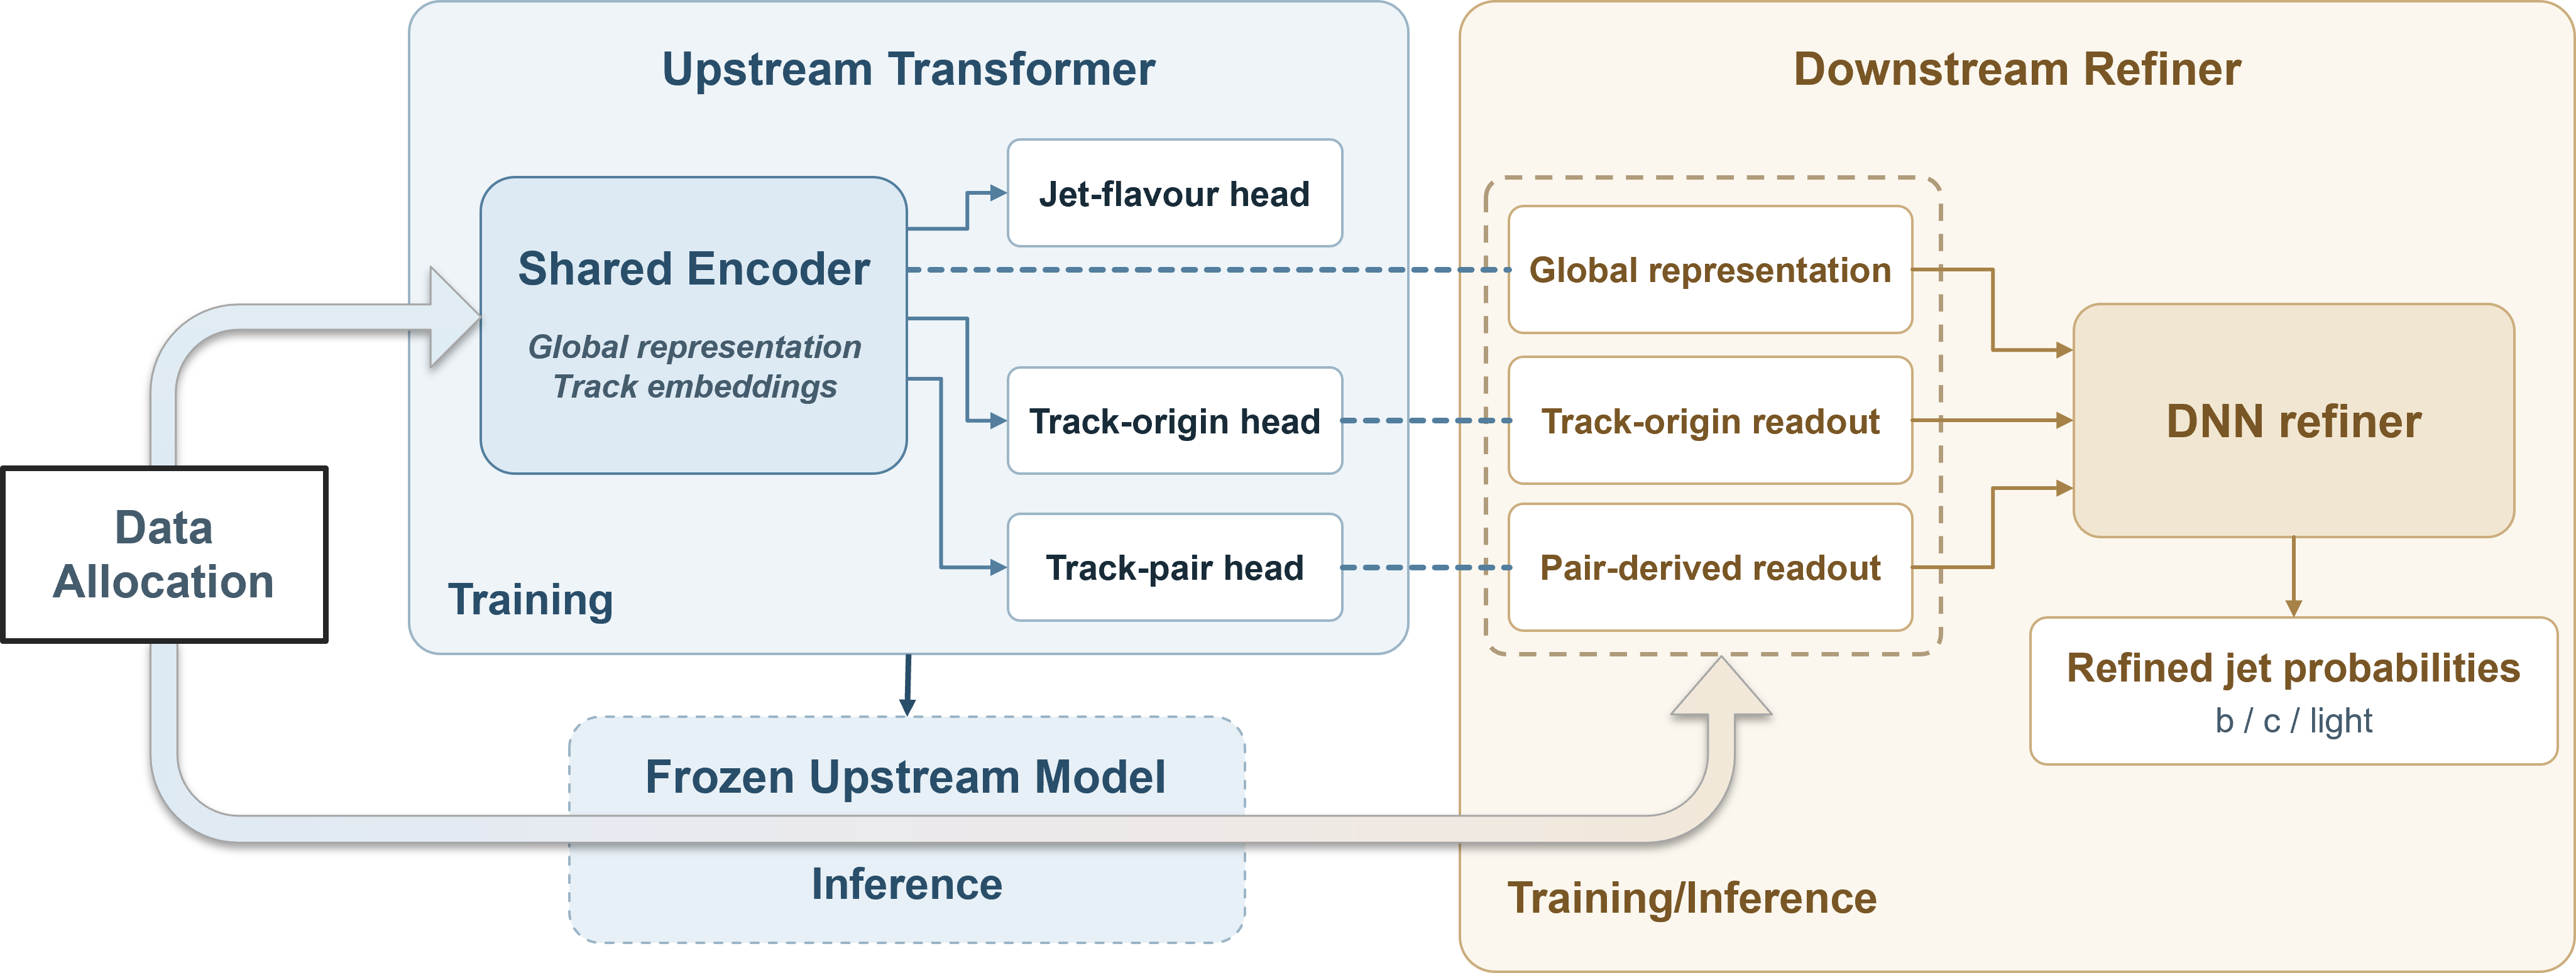

In [2]:
display(Image(filename=str(plots_dir / "figure" / "pipeline.png"), width=1000))

## Figure 2. Rejection curves for four refiners

Comparison with the corresponding upstream Transformer at 3M jets and a 75/25 allocation.

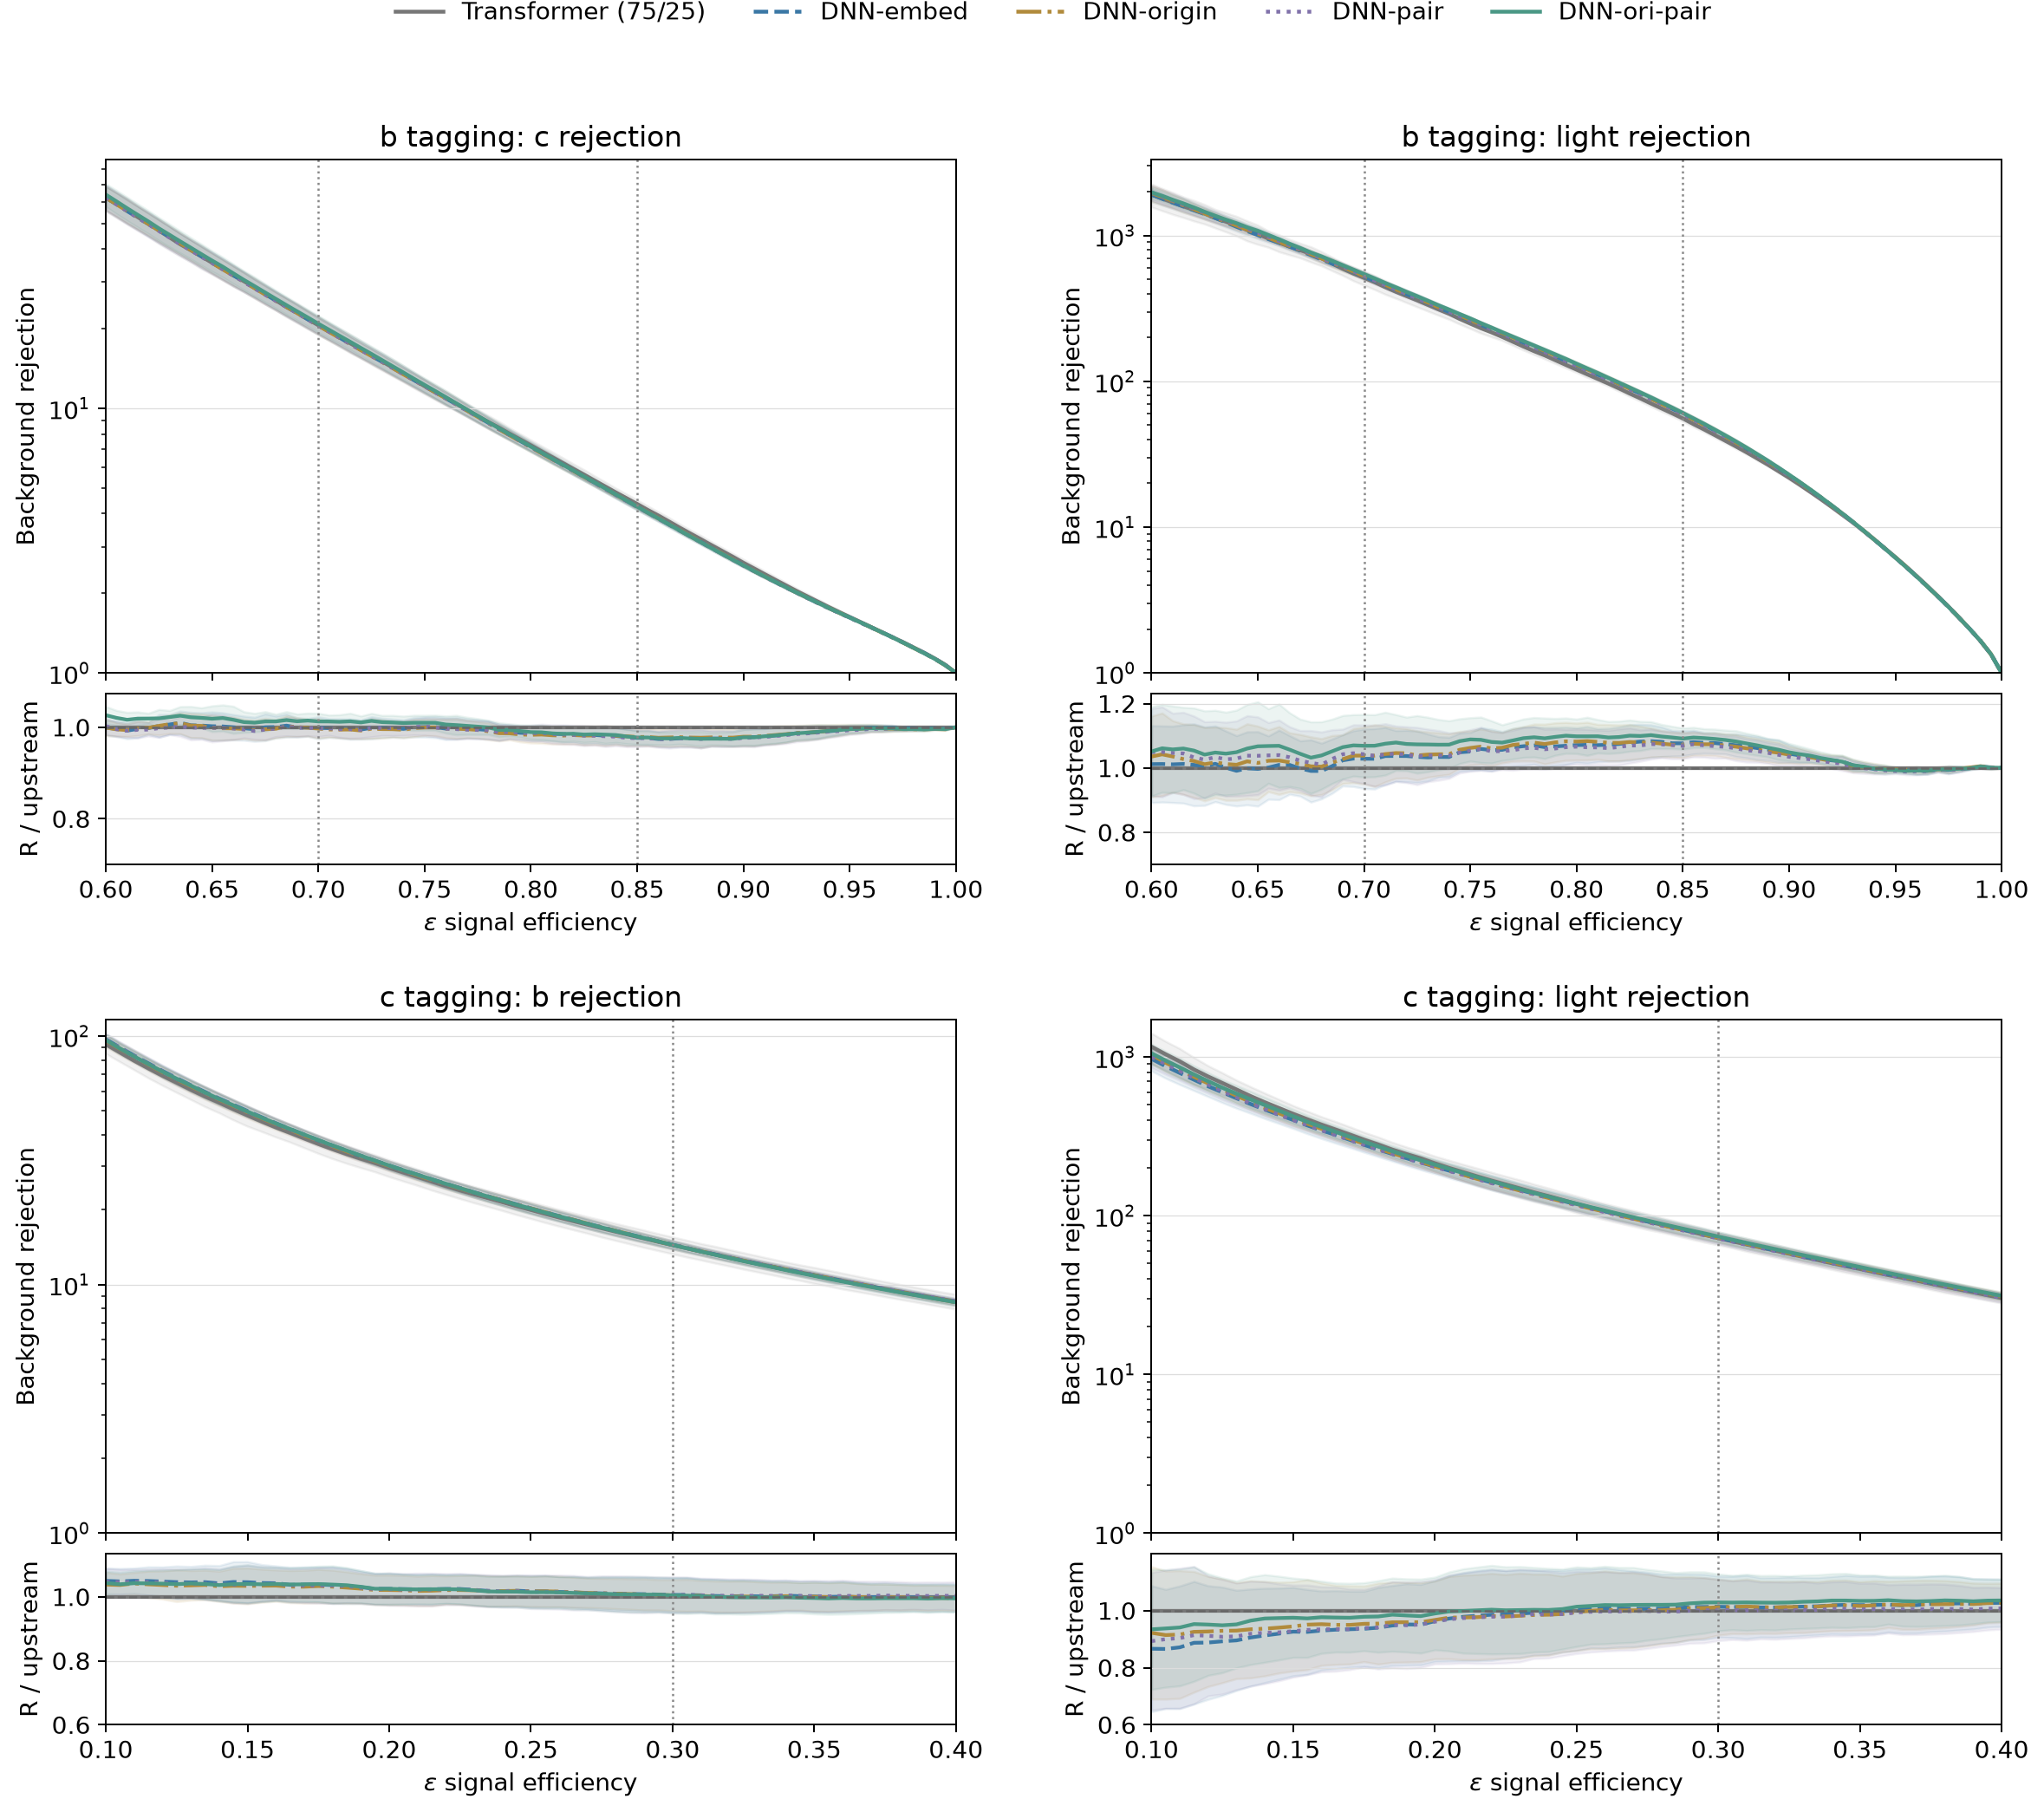

In [3]:
show_experimental_figure(
    "rejection_3m_own_f1_f2_f3.py",
    "rejection_3m_75_25_four_refiners.png",
)

## Figure 3. Training-data allocation at 3M jets

Rejection across six working points, with Transformer width references.

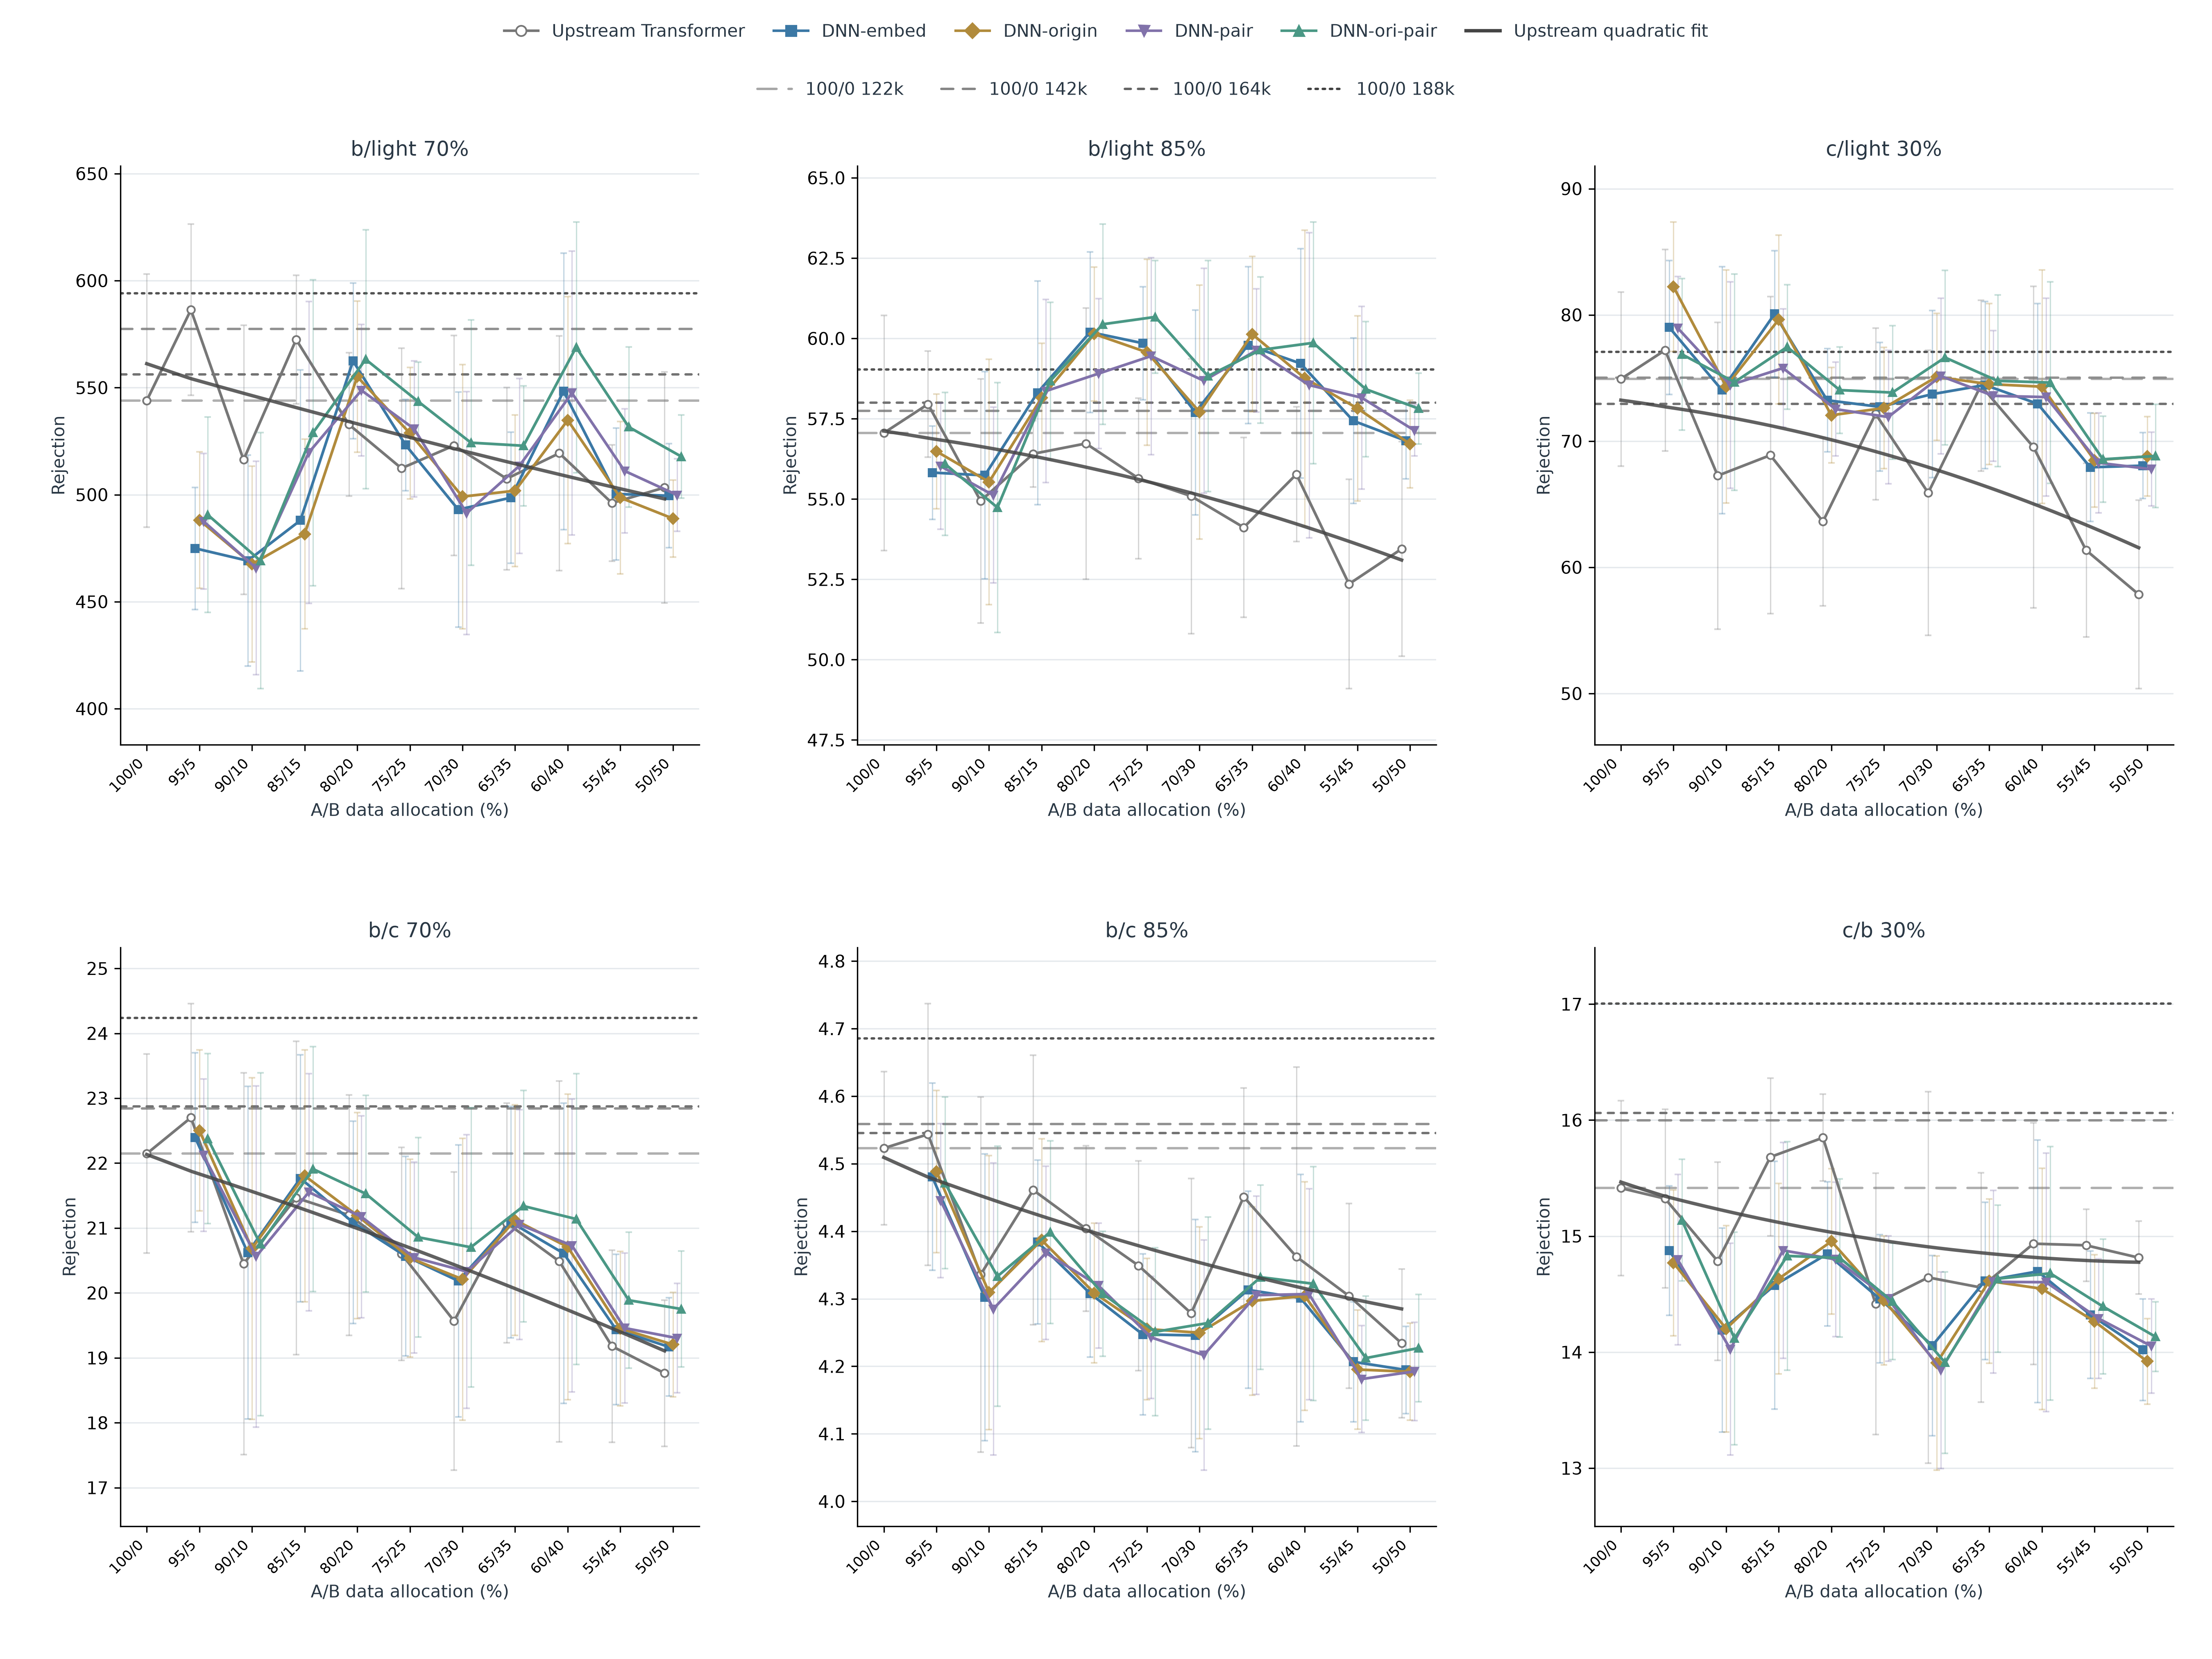

In [4]:
show_experimental_figure(
    "overlay_3m_width_scan_six_working_points.py",
    "wp_rejection_3m_width_scan_6wp.png",
)

## Figure 4. Auxiliary-loss weight scan

Transformer and DNN-ori-pair performance across 16 auxiliary-loss configurations.

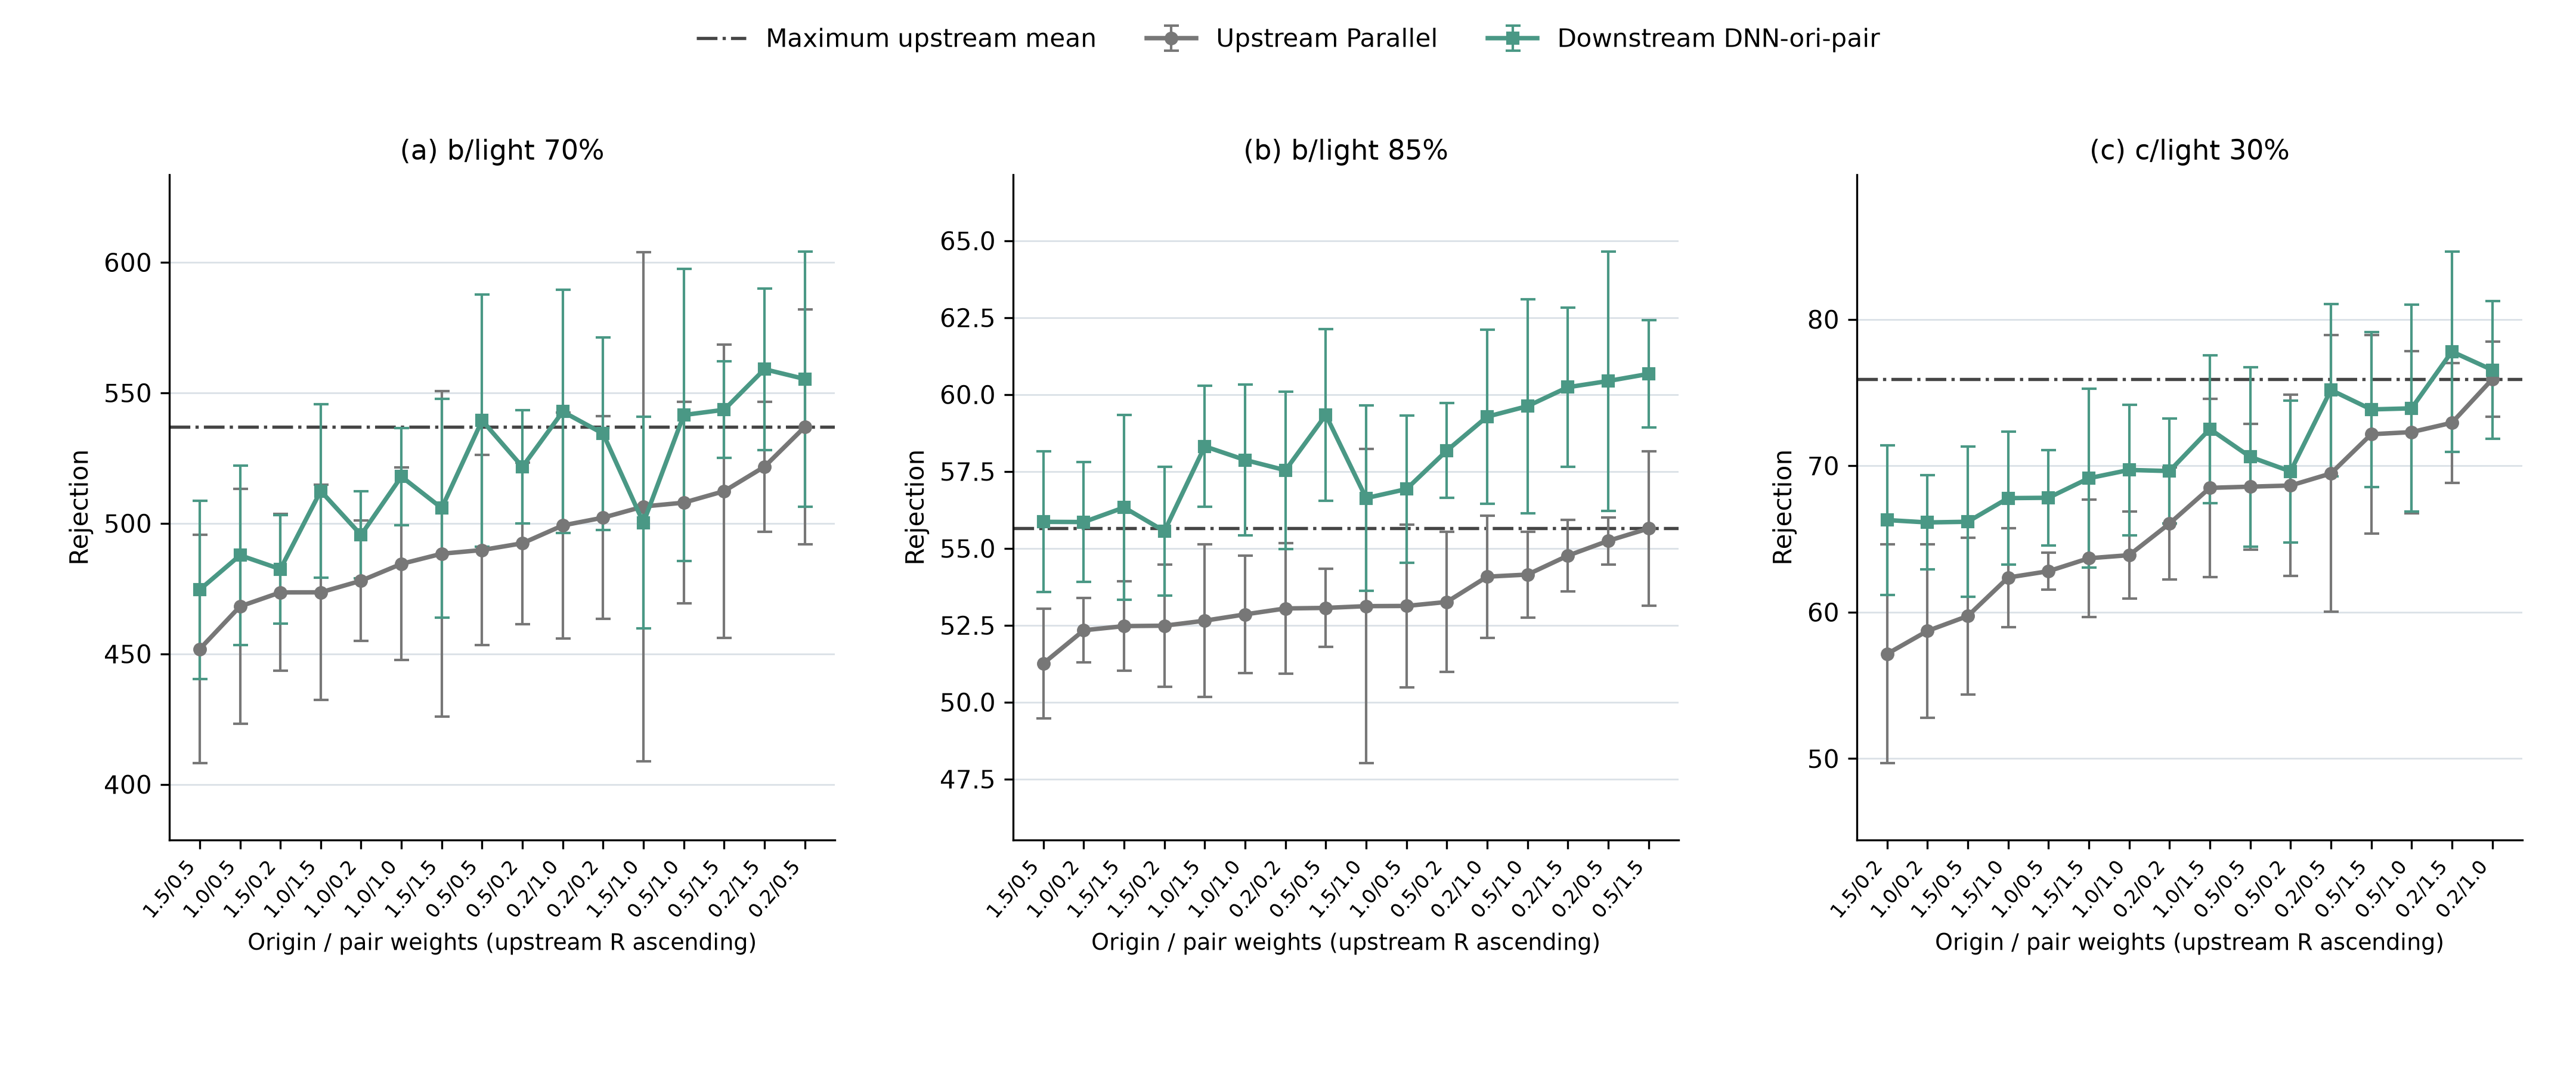

In [5]:
show_experimental_figure(
    "upstream_f3_sorted.py",
    "rejection_aux_weights_ori_ver.png",
)

## Figure 5. Reuse of upstream training data

DNN-embed and DNN-ori-pair at three light-jet rejection working points across data allocations.

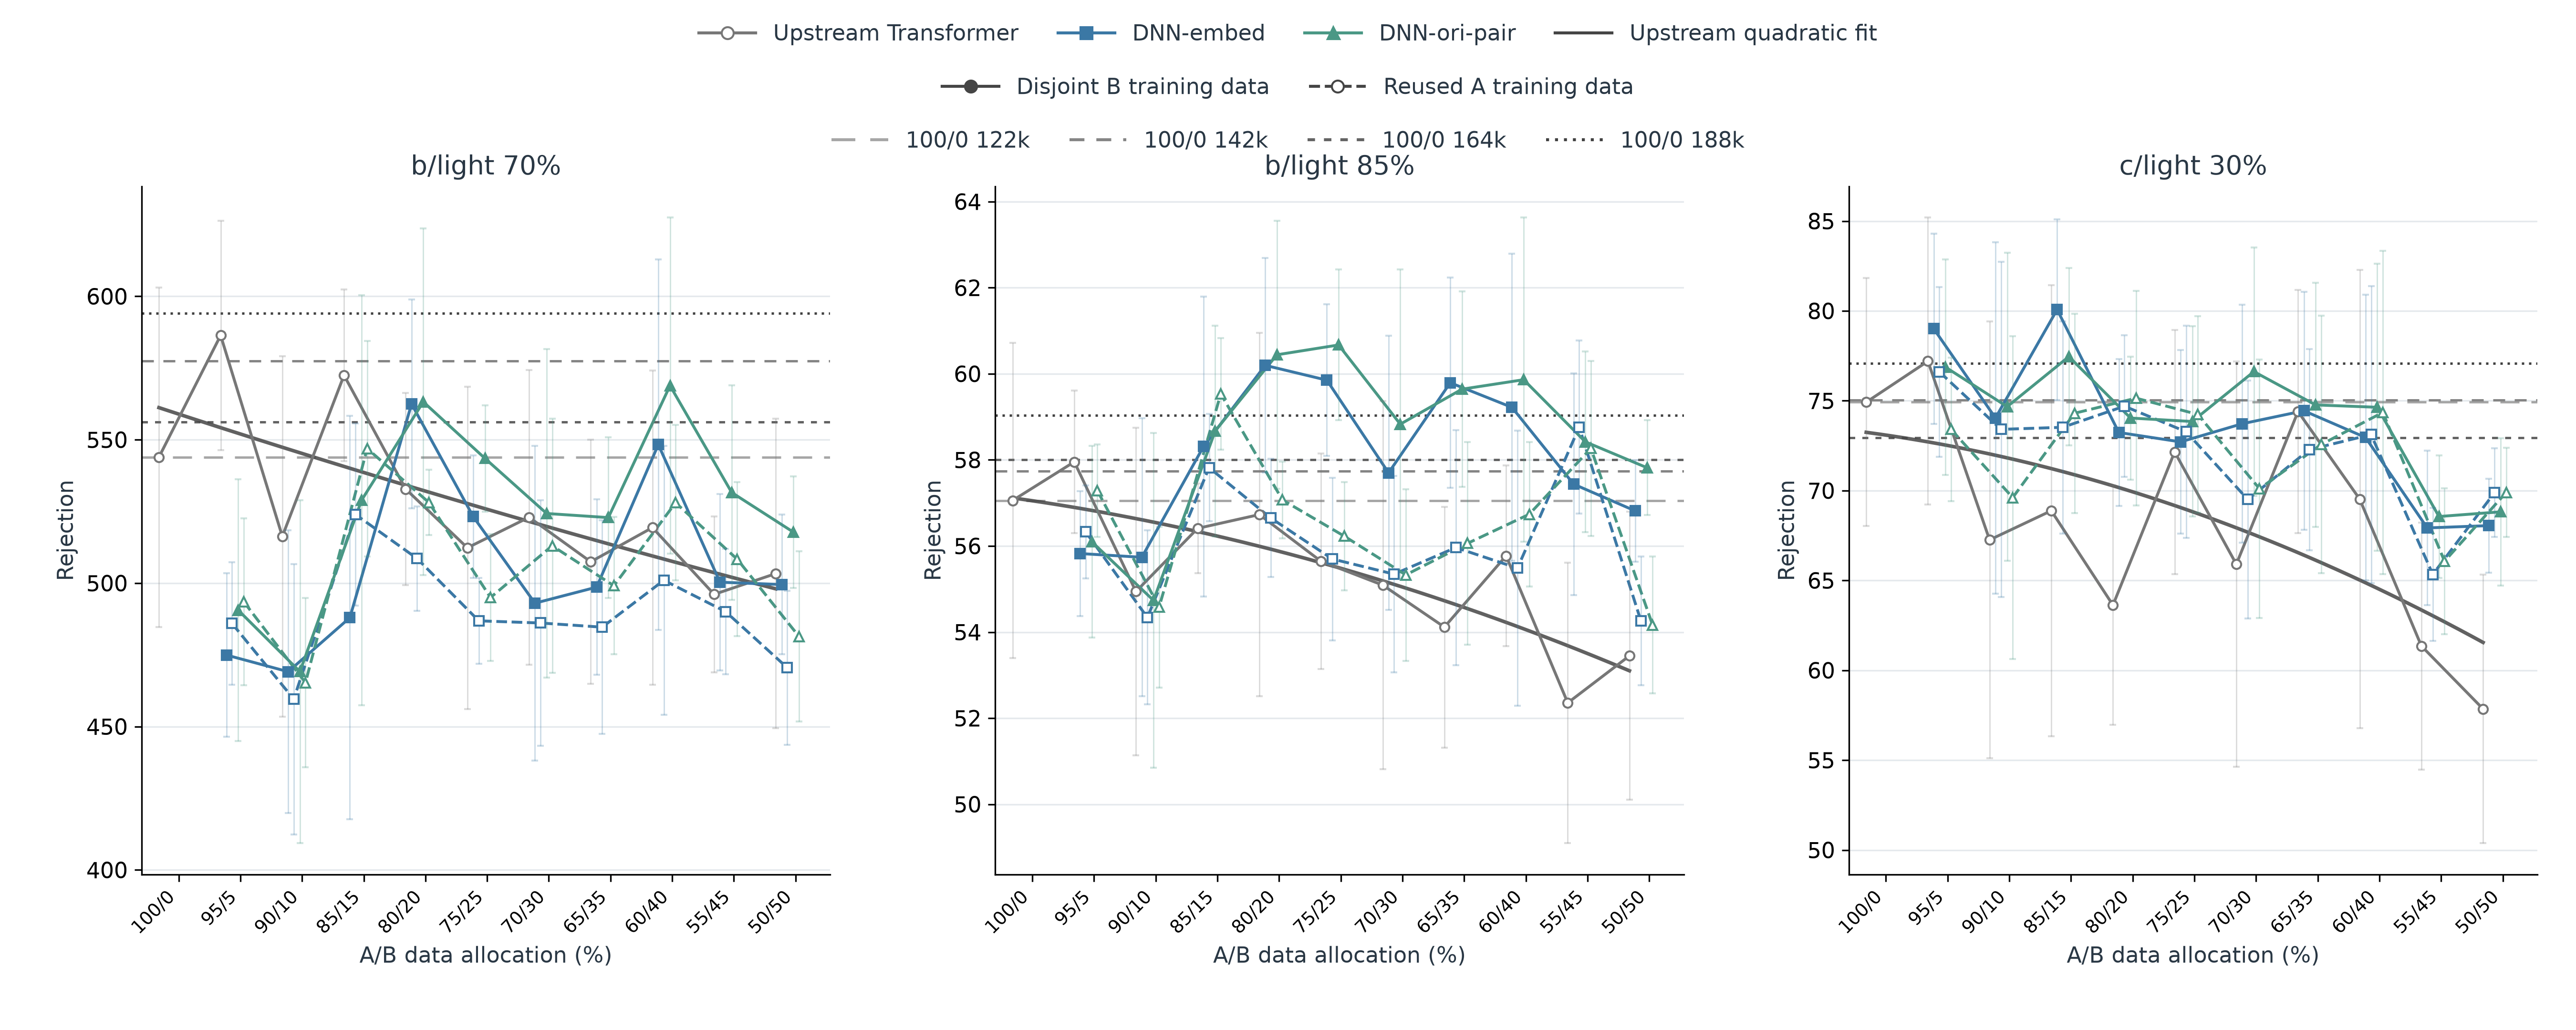

In [6]:
show_experimental_figure(
    "overlay_3m_width_scan_training_reuse_light.py",
    "wp_rejection_3m_width_scan_3wp_light_training_reuse_embed_ori_ver.png",
)

## Figure 6. Discriminant change versus secondary-vertex count

Discriminant changes at 3M jets and a 75/25 allocation.

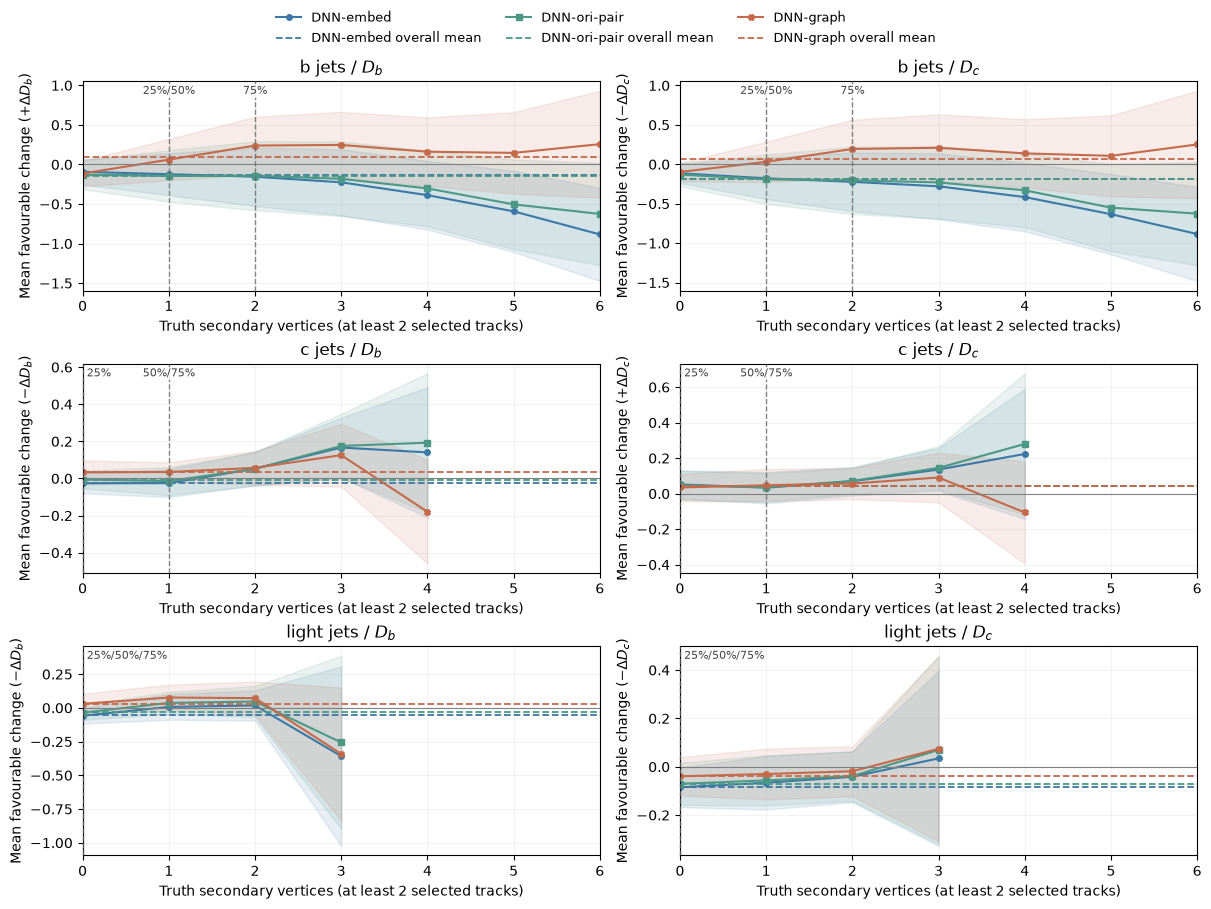

In [7]:
show_experimental_figure(
    "discriminant_vs_vertices.py",
    "discriminant_vs_vertices_3m_75_25.png",
)

## Figure 7. Training-data allocation at 1M and 5M jets

The appendix comparison across six working points.

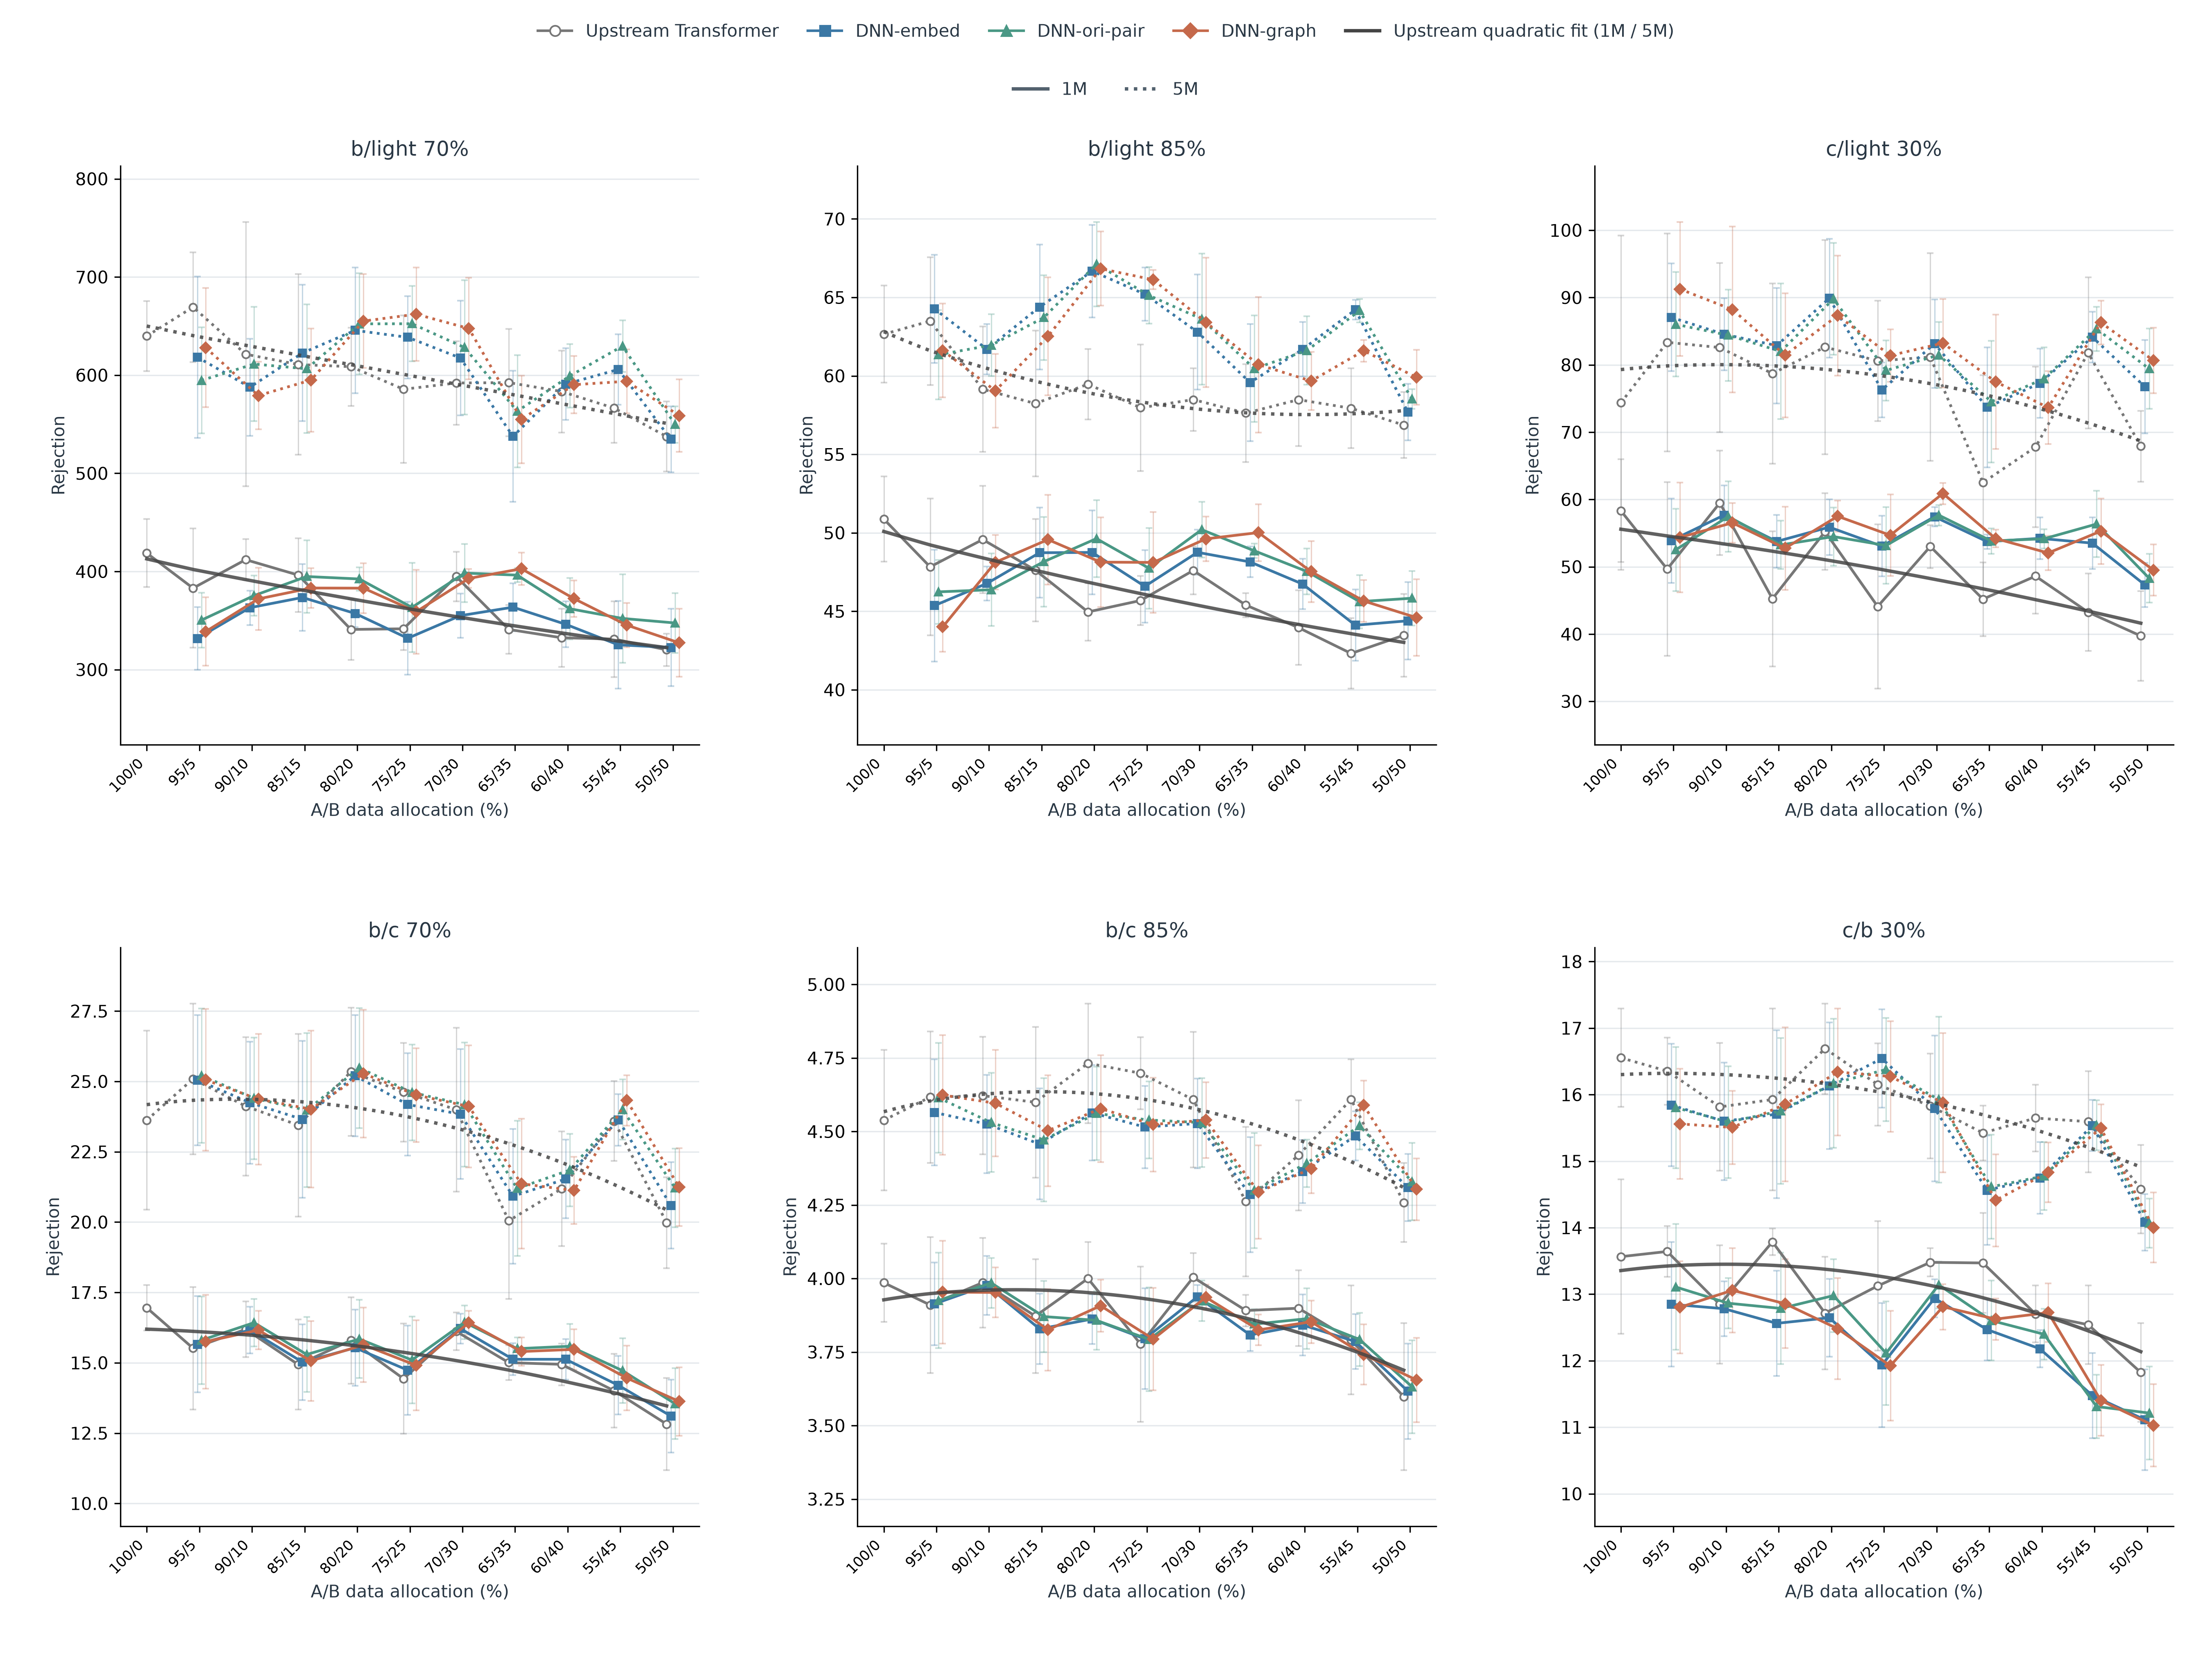

In [8]:
show_experimental_figure(
    "overlay_1m_5m_six_working_points.py",
    "wp_rejection_1m_5m_6wp.png",
)